# GPT-Image-2 image generation

### Installing Required Libraries

In [ ]:
%pip install -q openai pillow

### Setting up the Environment

In [6]:
from pathlib import Path
from dotenv import load_dotenv
import os

load_dotenv()

AZURE_OPENAI_ENDPOINT = os.getenv("AZURE_OPENAI_ENDPOINT")

AZURE_OPENAI_IMAGE_DEPLOYMENT = os.getenv("AZURE_OPENAI_IMAGE_DEPLOYMENT")

print(AZURE_OPENAI_ENDPOINT)
print(AZURE_OPENAI_IMAGE_DEPLOYMENT)

https://udemo-103-resource.services.ai.azure.com/openai/v1
gpt-image-2


### Creating the open ai client

In [7]:
from openai import OpenAI
from azure.identity import DefaultAzureCredential, get_bearer_token_provider

token_provider = get_bearer_token_provider(
    DefaultAzureCredential(exclude_environment_credential=True,
                           exclude_managed_identity_credential=True),
    "https://cognitiveservices.azure.com/.default"
)

client = OpenAI(
    base_url=AZURE_OPENAI_ENDPOINT,
    api_key=token_provider(),
)

### Helpers: save + display

In [8]:
import base64
from datetime import datetime
from PIL import Image

OUTPUT_DIR = Path("images")
OUTPUT_DIR.mkdir(exist_ok=True)


def save_b64_image(b64_data: str, filename: str) -> Path:
    out = OUTPUT_DIR / filename
    out.write_bytes(base64.b64decode(b64_data))
    return out


def show(path: Path):
    display(Image.open(path))

### Generate single image

C:\Users\jhussein\AppData\Local\Temp\ipykernel_32232\676106905.py:16: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  filename = f"gen_{datetime.utcnow().strftime('%Y%m%d_%H%M%S')}.png"


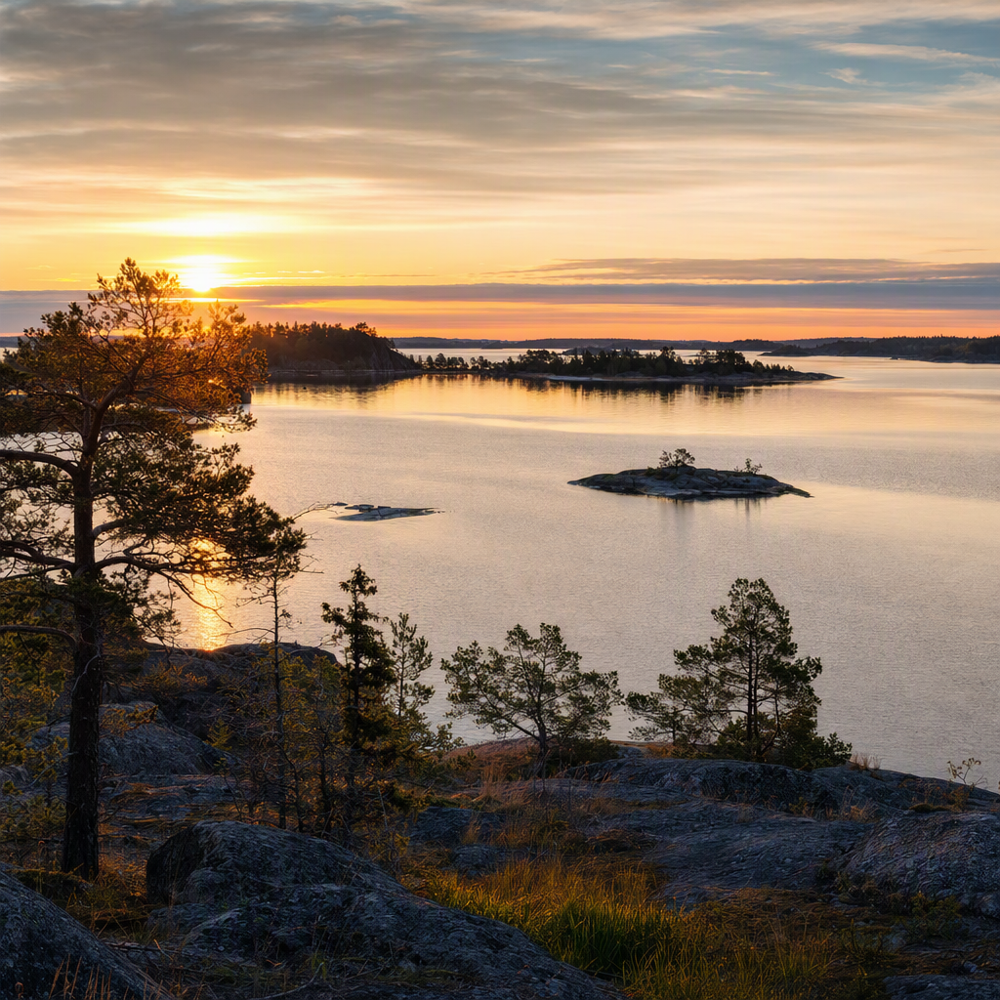

In [9]:
prompt = (
    "A realistic photo of Stockholm archipelago at sunrise, "
    "soft golden light, calm water, high detail"
)

result = client.images.generate(
    model=AZURE_OPENAI_IMAGE_DEPLOYMENT,
    prompt=prompt,
    n=1,
    size="1024x1024",
    quality="high",
    output_format="png",
)

b64 = result.data[0].b64_json
filename = f"gen_{datetime.utcnow().strftime('%Y%m%d_%H%M%S')}.png"
path = save_b64_image(b64, filename)

show(path)

### Generate multiple images (n up to 10)


C:\Users\jhussein\AppData\Local\Temp\ipykernel_32232\1968924697.py:13: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  ts = datetime.utcnow().strftime("%Y%m%d_%H%M%S")


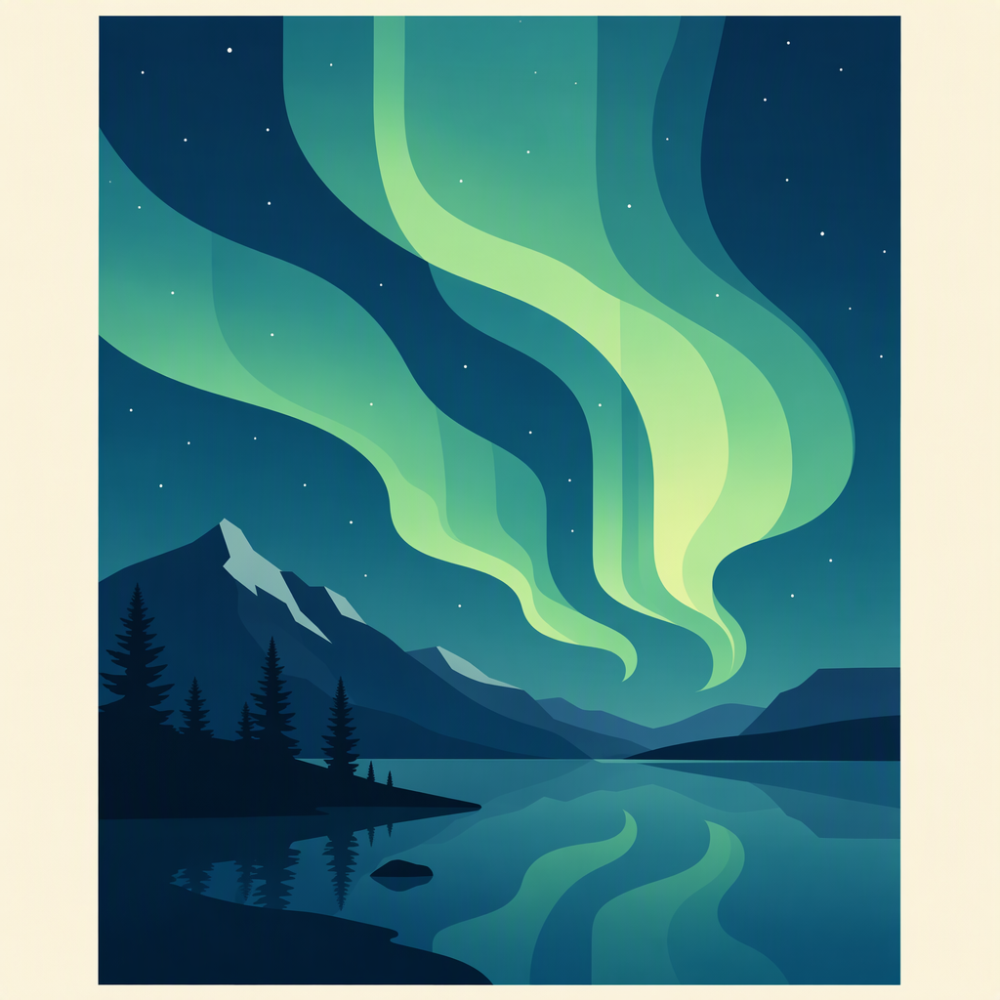

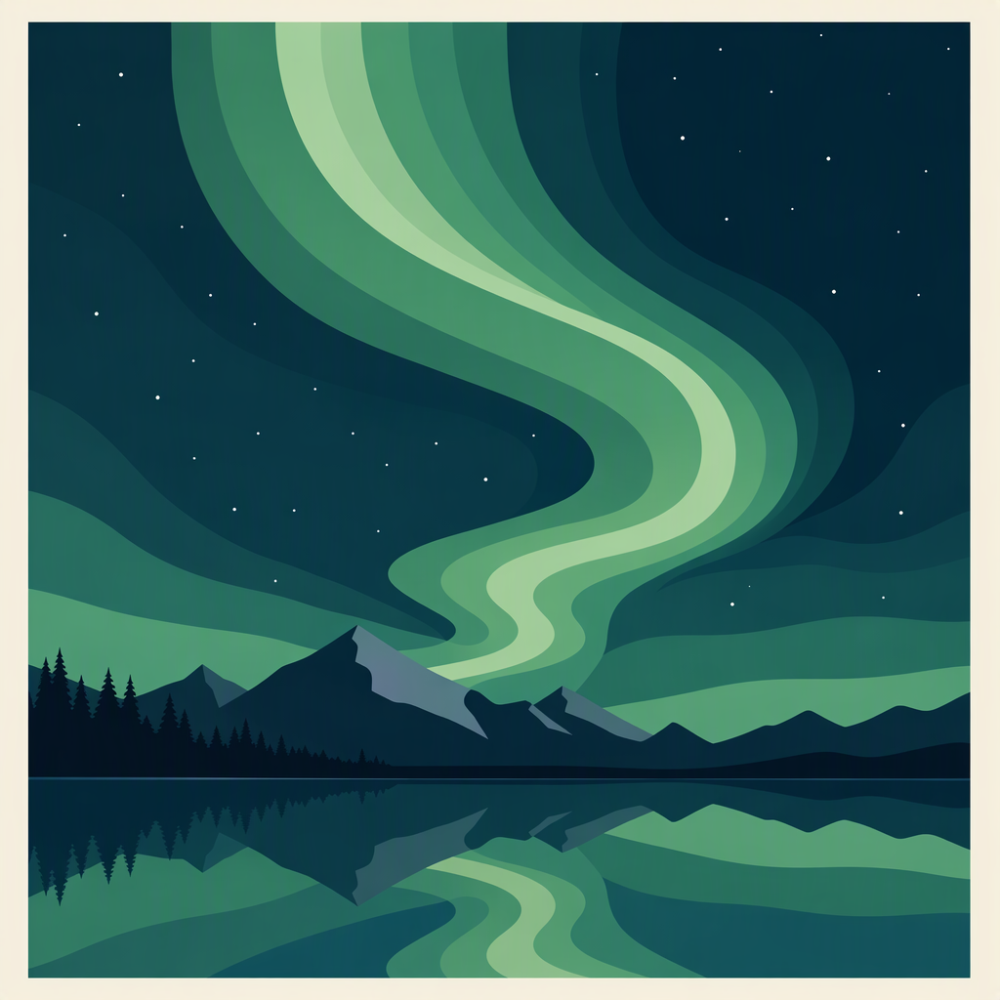

In [10]:
prompt = "Minimalist poster of a northern lights sky over a lake, flat design, clean shapes"

result = client.images.generate(
    model=AZURE_OPENAI_IMAGE_DEPLOYMENT,
    prompt=prompt,
    n=2,
    size="1024x1024",
    quality="medium",
    output_format="png",
)

paths = []
ts = datetime.utcnow().strftime("%Y%m%d_%H%M%S")
for i, item in enumerate(result.data, start=1):
    p = save_b64_image(item.b64_json, f"batch_{ts}_{i}.png")
    paths.append(p)

for p in paths:
    show(p)

### Streaming example (partial images)

C:\Users\jhussein\AppData\Local\Temp\ipykernel_14280\274357607.py:1: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  stream_ts = datetime.utcnow().strftime("%Y%m%d_%H%M%S")


Partial image 0


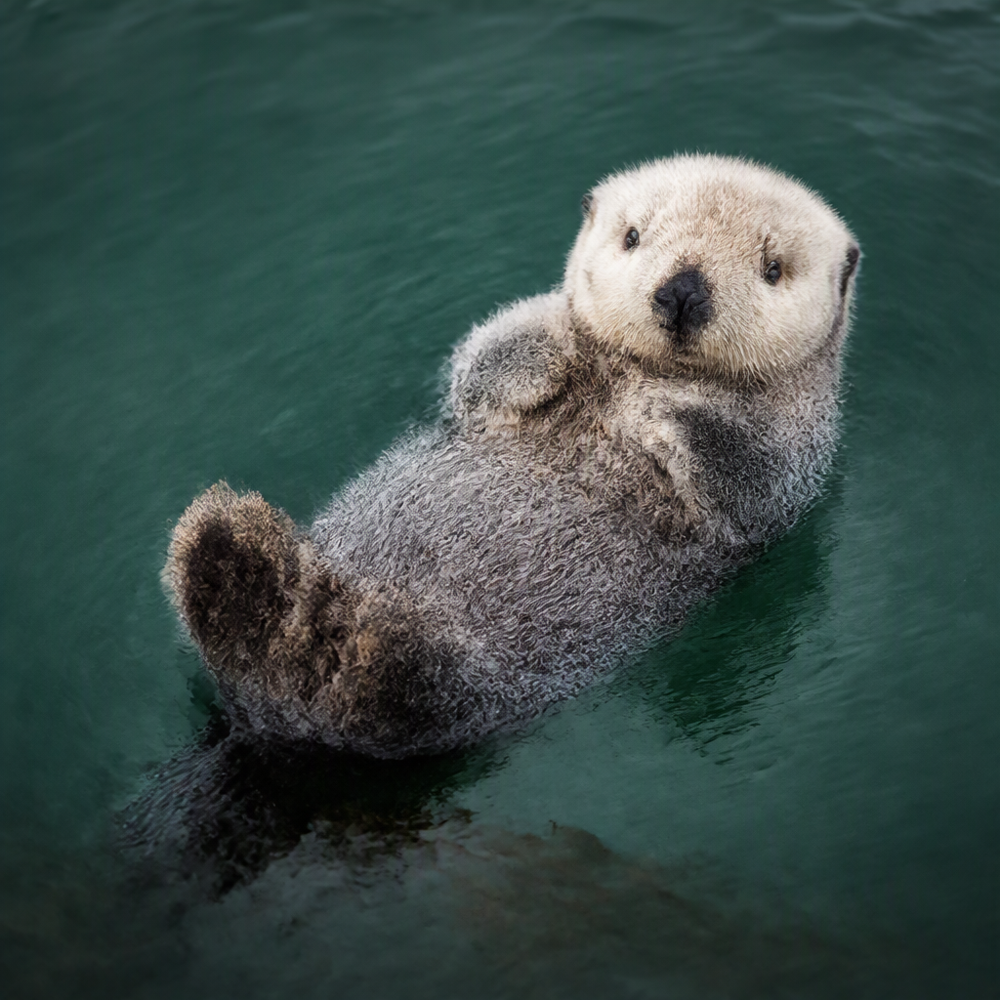

Completed: images\stream_20261016_101001_final.png


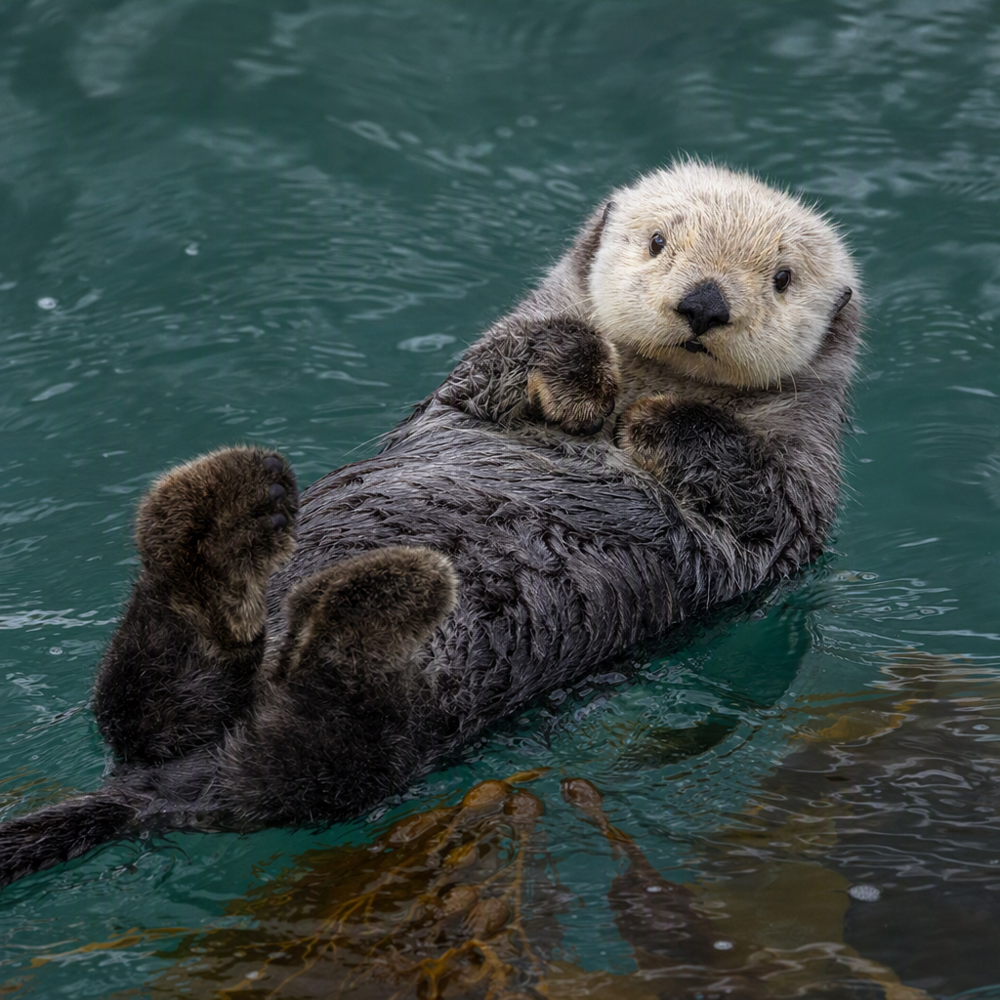

In [14]:
stream_ts = datetime.utcnow().strftime("%Y%m%d_%H%M%S")

with client.images.generate(
    model=AZURE_OPENAI_IMAGE_DEPLOYMENT,
    prompt="A cute baby sea otter floating on its back, photorealistic, high detail",
    n=1,
    size="1024x1024",
    quality="high",
    output_format="png",
    stream=True,
    partial_images=1,
) as image_stream:
    for event in image_stream:
        if event.type == "image_generation.partial_image":
            partial_path = save_b64_image(
                event.b64_json,
                f"stream_{stream_ts}_partial_{event.partial_image_index}.png",
            )
            print(f"Partial image {event.partial_image_index}")
            show(partial_path)

        elif event.type == "image_generation.completed":
            final_path = save_b64_image(
                event.b64_json,
                f"stream_{stream_ts}_final.png",
            )
            print(f"Completed: {final_path}")
            show(final_path)

### Common failure modes

In [13]:
def safe_generate(prompt: str, **kwargs):
    try:
        return client.images.generate(
            model=AZURE_OPENAI_IMAGE_DEPLOYMENT,
            prompt=prompt,
            **kwargs
        )
    except Exception as e:
        print("Generation failed.")
        print("Type:", type(e).__name__)
        print("Message (truncated):", str(e)[:800])
        raise


# Example:
_ = safe_generate("A peaceful forest path, cinematic lighting",
                  n=1, size="768x768", quality="medium", output_format="png")

Generation failed.
Type: BadRequestError
Message (truncated): Error code: 400 - {'error': {'message': "Invalid size '768x768'. Requested resolution is below the current minimum pixel budget.", 'type': 'image_generation_user_error', 'param': 'size', 'code': 'invalid_value'}}


BadRequestError: Error code: 400 - {'error': {'message': "Invalid size '768x768'. Requested resolution is below the current minimum pixel budget.", 'type': 'image_generation_user_error', 'param': 'size', 'code': 'invalid_value'}}